# 🧹 EDA Nivel Medio — Limpieza justificada, variables nuevas y análisis

Segunda parte del análisis. El notebook `01_eda_covid.ipynb` diagnosticó el dataset
(20.780 filas × 56 columnas, 15 columnas con >80% de nulos, 0 duplicados, `date` como entero).
Aquí **limpiamos justificando cada decisión**, detectamos atípicos, creamos variables,
agrupamos, medimos correlaciones y seguimos las **3 preguntas guía**:

1. ¿Qué estados vivieron la pandemia peor (más allá del tamaño del estado)?
2. ¿Hay relación entre lo que se testea y lo que ocurre en los hospitales?
3. ¿Cuándo fueron los peores momentos y coincidieron entre estados?

> **Salida:** al final guardamos el dataset limpio en `data/processed/covid_limpio.csv`
> y las figuras en `assets/` para el informe ejecutivo.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")

FIG_DIR = Path("../assets")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../data/raw/covid_tracking.csv")
df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
df = df.sort_values(["state", "date"]).reset_index(drop=True)
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas | {df['date'].min().date()} -> {df['date'].max().date()}")

20,780 filas x 56 columnas | 2020-01-13 -> 2021-03-07


---

## 1️⃣ Decisiones de limpieza (cada una, justificada)

Criterios que usamos, en orden de prioridad:

1. **Falta de datos:** si una columna tiene >80% de nulos no es analizable — la mayoría de sus valores no existen.
2. **Nula varianza:** columnas que siempre valen lo mismo no explican nada.
3. **Redundancia:** si una columna se puede calcular exactamente de otras, mantenemos solo una (y lo comprobamos).
4. **Metadatos del sistema:** marcas de sincronización de la API, no del fenómeno que estudiamos.
5. **Consistencia entre estados:** un dato que la mitad de los estados reporta y la otra mitad no, no es comparable.

Primero, listamos los problemas calculados (no a ojo):

In [2]:
# Problemas calculados directamente del dato
mas80 = sorted(df.columns[df.isna().mean() > 0.8].tolist())
constantes = sorted(c for c in df.columns if df[c].nunique(dropna=True) <= 1)

print(f"1) Columnas con >80% de nulos ({len(mas80)}):")
print("   ", ", ".join(mas80))
print(f"\n2) Columnas constantes o vacias ({len(constantes)}):")
print("   ", ", ".join(constantes))
print("\n3) Redundancia comprobada:")
print("   posNeg == positive + negative en TODAS las filas:",
      (df["posNeg"] == df["positive"].fillna(0) + df["negative"].fillna(0)).all())
mascara = df["hospitalized"].notna() & df["hospitalizedCumulative"].notna()
print("   hospitalized == hospitalizedCumulative donde ambas existen:",
      (df.loc[mascara, "hospitalized"] == df.loc[mascara, "hospitalizedCumulative"]).all())

1) Columnas con >80% de nulos (15):
    dataQualityGrade, grade, hospitalizedDischarged, inIcuCumulative, negativeTestsAntibody, negativeTestsPeopleAntibody, onVentilatorCumulative, pending, positiveTestsAntibody, positiveTestsAntigen, positiveTestsPeopleAntibody, positiveTestsPeopleAntigen, totalTestsAntigen, totalTestsPeopleAntibody, totalTestsPeopleAntigen

2) Columnas constantes o vacias (7):
    commercialScore, dataQualityGrade, grade, negativeRegularScore, negativeScore, positiveScore, score

3) Redundancia comprobada:
   posNeg == positive + negative en TODAS las filas: True
   hospitalized == hospitalizedCumulative donde ambas existen: True


In [3]:
decisiones = pd.DataFrame(
    [
        (f"{len(mas80)} columnas con >80% nulos",
         "tests de antigeno/anticuerpo, UCI/ventilacion acumuladas, pending, hospitalizedDischarged..."
         " (ver lista impresa arriba): la mayoria de sus valores no existen",
         "ELIMINAR: falta de datos"),
        (f"{len(constantes)} columnas constantes/vacias",
         "score comercial y hermanas: siempre 0; dataQualityGrade y grade: 100% vacias",
         "ELIMINAR: nula varianza"),
        ("hash, fips",
         "identificadores tecnicos: hash unico por fila; fips es el codigo del estado, "
         "redundante con la columna 'state'",
         "ELIMINAR: no aportan al analisis"),
        ("lastUpdateEt, dateModified, checkTimeEt, dateChecked, totalTestResultsSource",
         "metadatos de sincronizacion con la API (cuando se actualizo el registro)",
         "ELIMINAR: son del sistema, no del fenomeno"),
        ("posNeg, total, hospitalized",
         "duplicados comprobados arriba: posNeg = positive+negative (100% de las filas); "
         "hospitalized identica a hospitalizedCumulative; total es la version antigua de totalTestResults",
         "ELIMINAR: redundancia"),
        ("recovered",
         "42% de nulos: muchos estados dejaron de reportar curados y no hay criterio unico",
         "ELIMINAR: inconsistente entre estados"),
        ("deathConfirmed, deathProbable, probableCases",
         ">50% de nulos: el desglose entre casos/muertes confirmadas y probadas "
         "no lo reportan todos los estados",
         "ELIMINAR: 'death' y 'positive' ya resumen"),
        ("totalTestsViral, positiveTestsViral, negativeTestsViral, totalTestEncountersViral, "
         "totalTestsPeopleViral, totalTestsAntibody, positiveCasesViral, negative, negativeIncrease",
         "desgloses de pruebas con 30-76% de nulos; ninguna de las 3 preguntas necesita "
         "desglosar por tipo de prueba",
         "ELIMINAR: la variable canonica es totalTestResults"),
    ],
    columns=["columna(s)", "problema detectado", "decision"],
)
decisiones

,columna(s),problema detectado,decision
0,15 columnas con >80% nulos,"tests de antigeno/anticuerpo, UCI/ventilacion ...",ELIMINAR: falta de datos
1,7 columnas constantes/vacias,score comercial y hermanas: siempre 0; dataQua...,ELIMINAR: nula varianza
2,"hash, fips",identificadores tecnicos: hash unico por fila;...,ELIMINAR: no aportan al analisis
3,"lastUpdateEt, dateModified, checkTimeEt, dateC...",metadatos de sincronizacion con la API (cuando...,"ELIMINAR: son del sistema, no del fenomeno"
4,"posNeg, total, hospitalized",duplicados comprobados arriba: posNeg = positi...,ELIMINAR: redundancia
5,recovered,42% de nulos: muchos estados dejaron de report...,ELIMINAR: inconsistente entre estados
6,"deathConfirmed, deathProbable, probableCases",>50% de nulos: el desglose entre casos/muertes...,ELIMINAR: 'death' y 'positive' ya resumen
7,"totalTestsViral, positiveTestsViral, negativeT...",desgloses de pruebas con 30-76% de nulos; ning...,ELIMINAR: la variable canonica es totalTestRes...


In [4]:
# Aplicamos: nos quedamos con las 13 columnas que responden las preguntas
MANTENER = [
    "date", "state",
    "positive", "totalTestResults", "death",                     # acumulados clave
    "hospitalizedCumulative", "hospitalizedCurrently",
    "inIcuCurrently", "onVentilatorCurrently",                    # presion hospitalaria
    "positiveIncrease", "totalTestResultsIncrease",
    "deathIncrease", "hospitalizedIncrease",                      # incrementos diarios
]
ELIMINAR = [c for c in df.columns if c not in MANTENER]

df = df.drop(columns=ELIMINAR)
print(f"Antes: 56 columnas -> Ahora: {df.shape[1]} columnas (eliminadas: {len(ELIMINAR)})")
df.info(memory_usage="deep")

Antes: 56 columnas -> Ahora: 13 columnas (eliminadas: 43)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      20780 non-null  datetime64[ns]
 1   state                     20780 non-null  object        
 2   positive                  20592 non-null  float64       
 3   totalTestResults          20614 non-null  float64       
 4   hospitalizedCurrently     17339 non-null  float64       
 5   hospitalizedCumulative    12382 non-null  float64       
 6   inIcuCurrently            11636 non-null  float64       
 7   onVentilatorCurrently     9126 non-null   float64       
 8   death                     19930 non-null  float64       
 9   positiveIncrease          20780 non-null  int64         
 10  totalTestResultsIncrease  20780 non-null  int64         
 11  deathIncrease         

---

## 2️⃣ Valores faltantes: no todos los nulos son iguales

Antes de imputar, comprobamos **dónde** están los nulos. La distinción importa:

- `positive`, `death` y `totalTestResults` son **acumulados**: un nulo *antes* de que el estado
  empezara a reportar significa «aún no había registros», no «faltan datos». Y un nulo *en medio*
  de la serie significaría un hueco real.
- `hospitalizedCurrently`, `inIcuCurrently` y `onVentilatorCurrently` son **instantáneos**
  (pacientes ingresados *ese día*): un nulo **no** significa 0 — significa que el estado no lo reportó.

**¿Y por qué no imputar con la mediana?** Porque es una serie temporal: la mediana de un estado
durante todo el año aplastaría las olas (en julio había pocos ingresos, en enero muchísimos).
Imputar con la mediana inventaría una realidad plana que no existió. Esa es la razón
por la que aquí **no** se usa la mediana, aunque sea el método habitual.

In [5]:
# Diagnosticamos: ¿los nulos son previos al primer reporte, interiores o posteriores?
def mapa_nulos(col):
    previos = interiores = posteriores = 0
    for _, g in df.groupby("state"):
        s = g[col]
        if s.isna().sum() == 0:
            continue
        fv, lv = s.first_valid_index(), s.last_valid_index()
        if fv is None:
            previos += s.isna().sum()
            continue
        pos = [g.index.get_loc(i) for i in s.index[s.isna()]]
        fi, li = g.index.get_loc(fv), g.index.get_loc(lv)
        previos += sum(p < fi for p in pos)
        interiores += sum(fi < p < li for p in pos)
        posteriores += sum(p > li for p in pos)
    return previos, interiores, posteriores

for col in ["positive", "death", "totalTestResults",
            "hospitalizedCurrently", "inIcuCurrently", "onVentilatorCurrently"]:
    p, i, po = mapa_nulos(col)
    print(f"{col:26} previos={p:5} | interiores={i:4} | posteriores={po:4}")

positive                   previos=  188 | interiores=   0 | posteriores=   0
death                      previos=  850 | interiores=   0 | posteriores=   0


totalTestResults           previos=  166 | interiores=   0 | posteriores=   0


hospitalizedCurrently      previos= 2995 | interiores= 117 | posteriores= 329


inIcuCurrently             previos= 8437 | interiores= 409 | posteriores= 298
onVentilatorCurrently      previos=10176 | interiores= 222 | posteriores=1256


In [6]:
# Acumulados: TODOS sus nulos son previos al primer reporte (0 interiores) -> rellenar con 0
# significa 'aun no habia registros', que es cierto para un acumulado.
for col in ["positive", "death", "totalTestResults"]:
    assert mapa_nulos(col)[1] == 0, f"{col} tiene huecos interiores; revisar"
    df[col] = df[col].fillna(0)

# Instantaneos: rellenamos SOLO huecos internos con el ultimo valor conocido (ffill dentro del
# estado: un paciente no desaparece de un dia para otro), y respetamos los nulos iniciales
# (el estado aun no reportaba) y finales (dejo de reportar): no inventamos ingresos.
for col in ["hospitalizedCurrently", "inIcuCurrently", "onVentilatorCurrently"]:
    previo = df.groupby("state")[col].ffill()
    futuro = df.groupby("state")[col].bfill()
    df[col] = previo.where(futuro.notna(), np.nan)

print("Nulos restantes tras la limpieza:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

Nulos restantes tras la limpieza:
hospitalizedCurrently      3324
hospitalizedCumulative     8398
inIcuCurrently             8735
onVentilatorCurrently     11432


---

## 3️⃣ Valores negativos: no son errores, son correcciones

Los incrementos diarios (`deathIncrease`, `positiveIncrease`...) contienen valores negativos.
Esto **no es un fallo de dato**: los estados descubrían registros duplicados o de fechas
anteriores y los restaban el día que los corregían. Decisión: **no los borramos** (borrarlos
sería ocultar correcciones reales y sesgaría las sumas), pero **los documentamos** y para
visualizar tendencias usamos medias móviles de 7 días, que los absorben.

In [7]:
incrementos = ["positiveIncrease", "totalTestResultsIncrease", "deathIncrease", "hospitalizedIncrease"]
tabla_neg = pd.DataFrame({
    "n_negativos": {c: int((df[c] < 0).sum()) for c in incrementos},
    "pct": {c: round((df[c] < 0).mean() * 100, 2) for c in incrementos},
    "minimo": {c: int(df[c].min()) for c in incrementos},
})
display(tabla_neg)

# Los 5 peores ejemplos, para documentarlos en el informe
df.nsmallest(5, "deathIncrease")[["date", "state", "deathIncrease", "death"]]

,n_negativos,pct,minimo
positiveIncrease,24,0.12,-7757
totalTestResultsIncrease,49,0.24,-130545
deathIncrease,73,0.35,-201
hospitalizedIncrease,88,0.42,-12257


,date,state,deathIncrease,death
15231,2020-04-23,PA,-201,1421.0
1092,2021-02-28,AR,-174,5243.0
19584,2020-12-11,WA,-166,2850.0
14439,2021-03-02,OH,-157,17189.0
12151,2021-01-09,NE,-78,1733.0


---

## 4️⃣ Valores atípicos (outliers) — método IQR

Regla de Tukey: es atípico quien está a más de **1,5 × Rango Intercuartílico (IQR)**
por debajo de Q1 o por encima de Q3. Calculamos los límites y los contamos;
luego miramos un boxplot de las muertes diarias por estado.

**Decisión que veremos:** ¿eliminarlos? No. La mayoría de estos «atípicos» son días reales
de máximo de una ola o correcciones de registro gigantes (un estado que limpia 2.500
muertes de golpe un martes). Eliminarlos sería mentir sobre la magnitud de la pandemia.
Se **conservan**; para leer tendencias usamos media móvil de 7 días.

Q1=0 | Q3=24 | IQR=24 | limite superior=60
Atipicos: 2,201 de 20,780 filas (10.6%)

Decision: SE CONSERVAN (son dias reales de maximo o correcciones de registro).


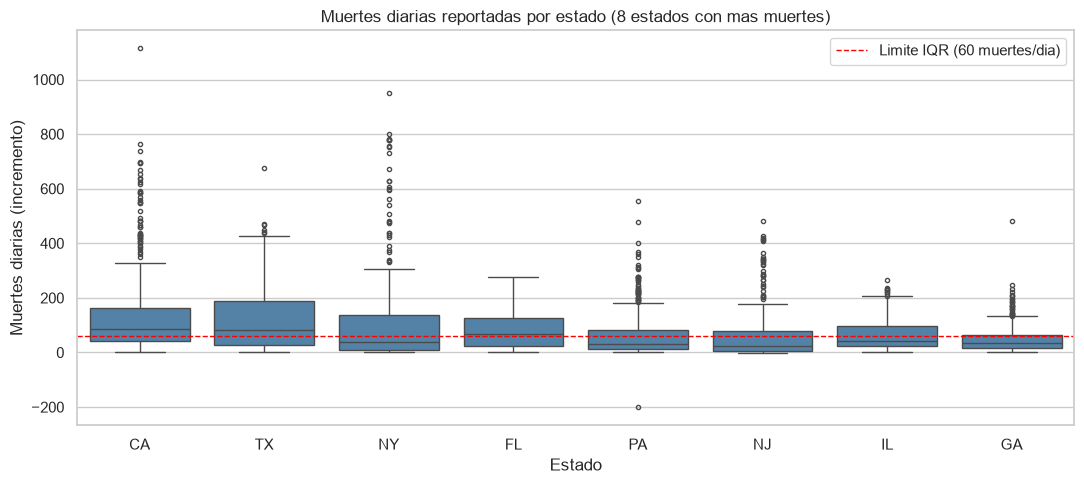

In [8]:
q1, q3 = df["deathIncrease"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
atipicos = df[df["deathIncrease"] > limite_sup]

print(f"Q1={q1:.0f} | Q3={q3:.0f} | IQR={iqr:.0f} | limite superior={limite_sup:.0f}")
print(f"Atipicos: {len(atipicos):,} de {len(df):,} filas ({len(atipicos)/len(df)*100:.1f}%)")
print("\nDecision: SE CONSERVAN (son dias reales de maximo o correcciones de registro).")

# Boxplot: muertes diarias en los 8 estados con mas muertes
top8 = (df.groupby("state")["death"].max().nlargest(8).index.tolist())
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df[df["state"].isin(top8)], x="state", y="deathIncrease",
            order=top8, color="steelblue", fliersize=3)
ax.axhline(limite_sup, color="red", ls="--", lw=1, label=f"Limite IQR ({limite_sup:.0f} muertes/dia)")
ax.set_title("Muertes diarias reportadas por estado (8 estados con mas muertes)")
ax.set_xlabel("Estado")
ax.set_ylabel("Muertes diarias (incremento)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_boxplot_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 5️⃣ Variables nuevas (feature engineering)

Creamos 4 variables que no venían en el dato y que desbloquean el análisis:

| Variable | Cómo se calcula | Para qué sirve |
|---|---|---|
| `mes` | partes de la fecha (`YYYY-MM`) | análisis mensual y orden temporal |
| `dia_semana` | día de la semana de `date` | detectar el patrón de reporte (los lunes se acumulan muertes del fin de semana) |
| `positividad_pct` | `positiveIncrease / totalTestResultsIncrease × 100` | **ratio**: ¿qué % de las pruebas dieron positivas? Compara estados con justicia |
| `grupo_muertes` | terciles de muertes totales por estado (qcut) | rangos Alto/Medio/Bajo para comparar grupos |

La positividad necesita cuidados: solo se calcula cuando ambos incrementos son positivos
(un día negativo es una corrección, no una tasa) y se recorta a 100% — un porcentaje
no puede superar el 100%, por encima son desfases entre fechas de reporte.

In [9]:
# 1) y 2) partes de la fecha
df["mes"] = df["date"].dt.to_period("M").astype(str)
df["dia_semana"] = df["date"].dt.day_name()

# 3) ratio de positividad, con sus cuidados
valido = (df["positiveIncrease"] > 0) & (df["totalTestResultsIncrease"] > 0)
df["positividad_pct"] = np.where(
    valido,
    (df["positiveIncrease"] / df["totalTestResultsIncrease"] * 100).clip(upper=100),
    np.nan,
)

print(f"Positividad calculada en {df['positividad_pct'].notna().sum():,} de {len(df):,} dias")
df[["date", "state", "mes", "dia_semana", "positividad_pct"]].head(3)

Positividad calculada en 18,419 de 20,780 dias


,date,state,mes,dia_semana,positividad_pct
0,2020-03-06,AK,2020-03,Friday,NaN
1,2020-03-07,AK,2020-03,Saturday,NaN
2,2020-03-08,AK,2020-03,Sunday,NaN


---

## 6️⃣ Agrupar y resumir: `groupby`, `agg` y `pivot_table`

Una fila por estado con lo que cada uno acumuló al final de la serie. Aquí es donde
`grupo_muertes` (variable nueva 4) entra en escena.

In [10]:
resumen = (
    df.groupby("state")
    .agg(
        muertes=("death", "max"),
        casos=("positive", "max"),
        pruebas=("totalTestResults", "max"),
        hosp_pico=("hospitalizedCurrently", "max"),
        dias_reportados=("date", "count"),
    )
    .sort_values("muertes", ascending=False)
)
# Positividad global del estado: suma de positivos / suma de pruebas (no la media de medias)
suma = df.groupby("state")[["positiveIncrease", "totalTestResultsIncrease"]].sum()
resumen["positividad_global_pct"] = (suma["positiveIncrease"] / suma["totalTestResultsIncrease"] * 100).round(1)
resumen["muertes_por_mil_pruebas"] = (resumen["muertes"] / resumen["pruebas"] * 1000).round(1)

# Variable nueva 4: rangos de muertes (terciles)
resumen["grupo_muertes"] = pd.qcut(resumen["muertes"], 3, labels=["Bajo", "Medio", "Alto"])

print("Top 10 estados por muertes registradas:")
display(resumen.head(10).round(1))
print("\nDistribucion por grupo:")
display(resumen.groupby("grupo_muertes", observed=True)[["muertes", "casos", "positividad_global_pct"]].median().round(1))

Top 10 estados por muertes registradas:


,muertes,casos,pruebas,hosp_pico,dias_reportados,positividad_global_pct,muertes_por_mil_pruebas,grupo_muertes
state,,,,,,,,
CA,54124.0,3501394.0,49646014.0,22851.0,369,7.1,1.1,Alto
TX,44451.0,2686818.0,19907384.0,14218.0,370,13.5,2.2,Alto
NY,39029.0,1681169.0,39695100.0,18825.0,371,4.2,1.0,Alto
FL,32266.0,1909209.0,22339182.0,9520.0,404,8.5,1.4,Alto
PA,24349.0,948643.0,10681716.0,6346.0,370,8.9,2.3,Alto
NJ,23574.0,812609.0,10999550.0,8270.0,392,7.4,2.1,Alto
IL,23014.0,1198335.0,18640190.0,6175.0,369,6.4,1.2,Alto
GA,17906.0,1023487.0,7359069.0,6108.0,369,13.9,2.4,Alto
OH,17656.0,978471.0,10257157.0,5296.0,368,9.5,1.7,Alto



Distribucion por grupo:


,muertes,casos,positividad_global_pct
grupo_muertes,,,
Bajo,1030.0,56886.0,6.2
Medio,5229.0,311199.5,7.8
Alto,16658.0,826454.0,8.9


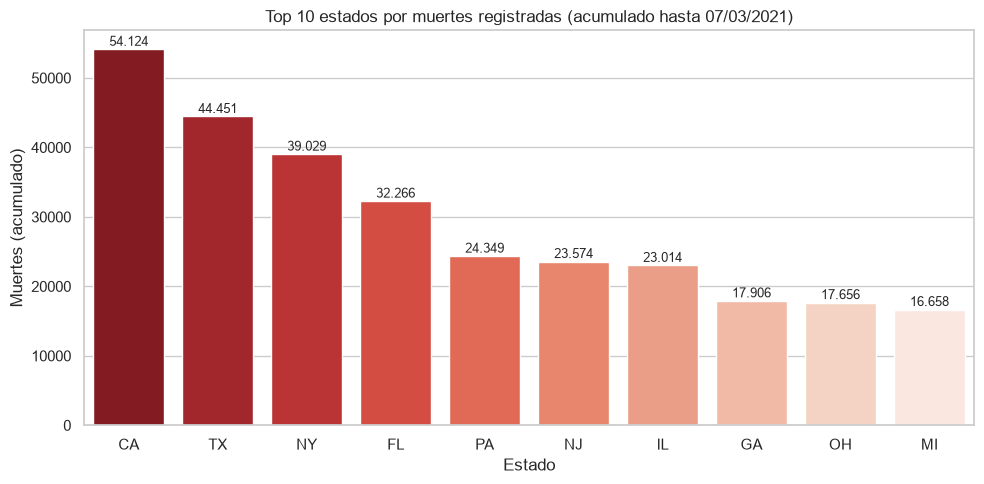

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
top10 = resumen.head(10)["muertes"]
sns.barplot(x=top10.index, y=top10.values, hue=top10.index, palette="Reds_r", legend=False, ax=ax)
for i, v in enumerate(top10.values):
    ax.text(i, v + 500, f"{int(v):,}".replace(",", "."), ha="center", fontsize=9)
ax.set_title("Top 10 estados por muertes registradas (acumulado hasta 07/03/2021)")
ax.set_xlabel("Estado")
ax.set_ylabel("Muertes (acumulado)")
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_top10_muertes.png", dpi=150, bbox_inches="tight")
plt.show()

state,CA,FL,NY,PA,TX
mes,,,,,
2020-03,1173.0,NaN,4268.0,NaN,196.0
2020-04,4053.0,NaN,15874.0,2478.0,1294.0
2020-05,4519.0,NaN,6512.0,1975.0,1672.0
2020-06,4843.0,NaN,1756.0,891.0,3103.0
2020-07,8056.0,8700.0,755.0,671.0,9812.0
2020-08,6376.0,5824.0,522.0,567.0,6442.0
2020-09,3818.0,2649.0,477.0,479.0,3442.0
2020-10,3087.0,2147.0,890.0,868.0,4314.0
2020-11,5044.0,3216.0,2088.0,2706.0,7318.0


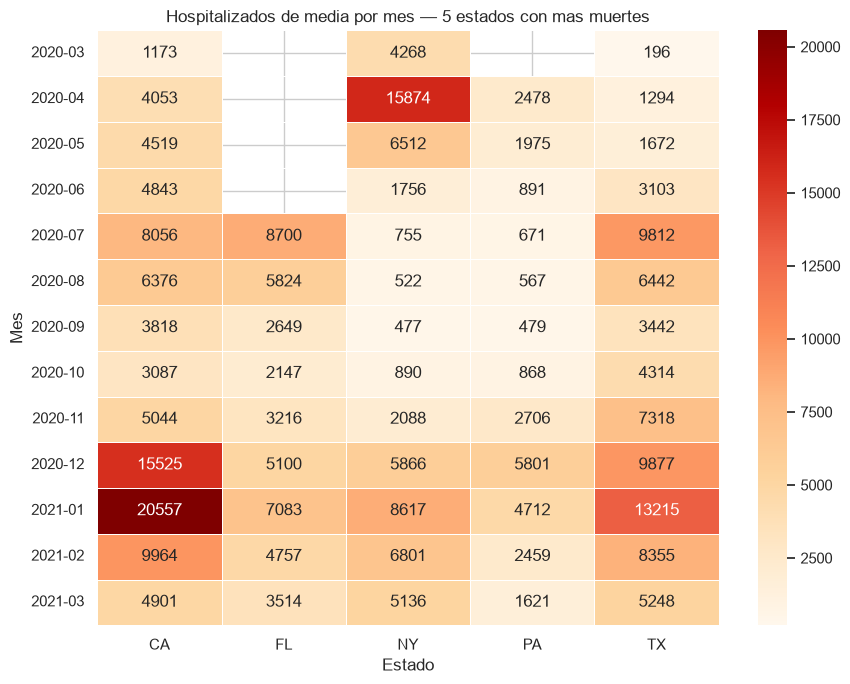

In [12]:
# Tabla dinamica: media mensual de hospitalizados en los 5 estados con mas muertes
top5 = resumen.head(5).index.tolist()
pivot = (
    df[df["state"].isin(top5)]
    .pivot_table(index="mes", columns="state", values="hospitalizedCurrently", aggfunc="mean")
    .round(0)
)
display(pivot)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="OrRd", linewidths=0.5, ax=ax)
ax.set_title("Hospitalizados de media por mes — 5 estados con mas muertes")
ax.set_xlabel("Estado")
ax.set_ylabel("Mes")
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_pivot_hospitales.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 7️⃣ Matriz de correlación (heatmap)

La correlación de Pearson va de -1 a +1: mide si dos variables suben y bajan juntas.
**Ojo:** correlación no implica causa — y aquí muchas columnas son acumuladas,
así que comparten tendencia temporal (todo sube durante la pandemia, eso infla los coeficientes).

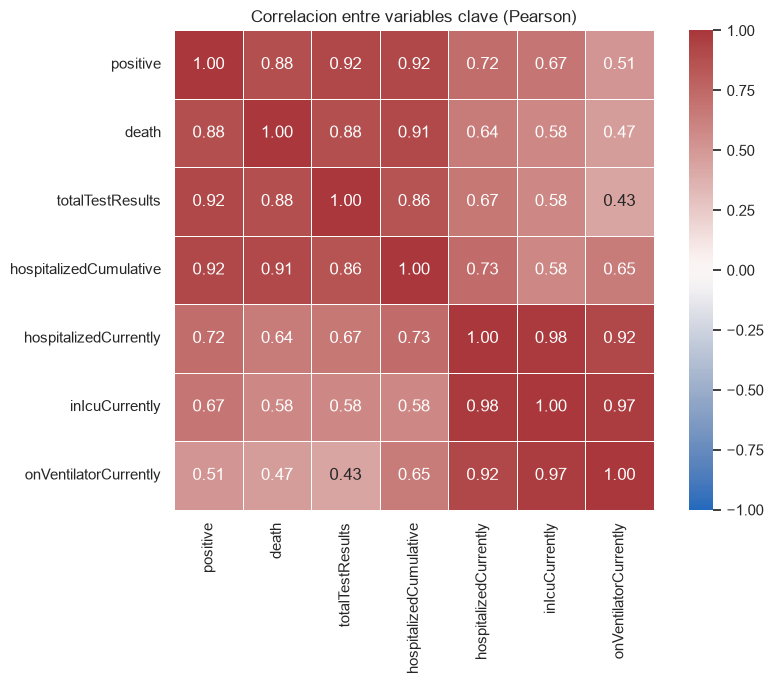

In [13]:
cols_corr = ["positive", "death", "totalTestResults", "hospitalizedCumulative",
             "hospitalizedCurrently", "inIcuCurrently", "onVentilatorCurrently"]
corr = df[cols_corr].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlacion entre variables clave (Pearson)")
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_correlacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación de la lectura:**

- `hospitalizedCurrently` ↔ `inIcuCurrently` (**0.98**) y con `onVentilatorCurrently` (**0.92**):
  son la misma historia en profundidades distintas — quien necesita UCI, necesita respirador.
  Prácticamente redundantes: para el informe basta con usar hospitalizados.
- `positive` ↔ `totalTestResults` (**0.92**): más pruebas, más casos detectados.
  Es una correlación mecánica (más esfuerzo de testeo = más hallazgo), **no** significa que
  testear contagie.
- `positive` ↔ `death` (**0.88**): más casos registrados se asocian a más muertes, con un
  desfase temporal de semanas que esta tabla plana no captura (lo veremos en la tendencia).
- `death` ↔ `hospitalizedCurrently` (**0.64**), más baja: las hospitalizaciones son diarias
  (suben y bajan con las olas) mientras las muertes son acumuladas — cuentas distintas.

> Todos los valores son positivos y altos porque **todo crece con el tiempo**: esta matriz
confirma coherencia interna del dataset, no causalidad.

### 🔗 La misma relación, vista punto a punto (dispersión)

Si la correlación es un número, el *scatter* es la foto. Van dos relaciones que
sostienen las conclusiones del informe:

- **Pruebas diarias vs. hospitalizados**: suben juntos porque ambos responden al
  mismo virus (las olas), **no** porque testear enferme a nadie.
- **Positividad de hace 2 semanas vs. hospitalizados de hoy**: cuando la positividad
  supera el 5 % (línea de referencia), las camas se llenan semanas después. Desplazar
  la positividad 14 días hacia delante es la transformación justificada aquí: el
  efecto no es instantáneo.

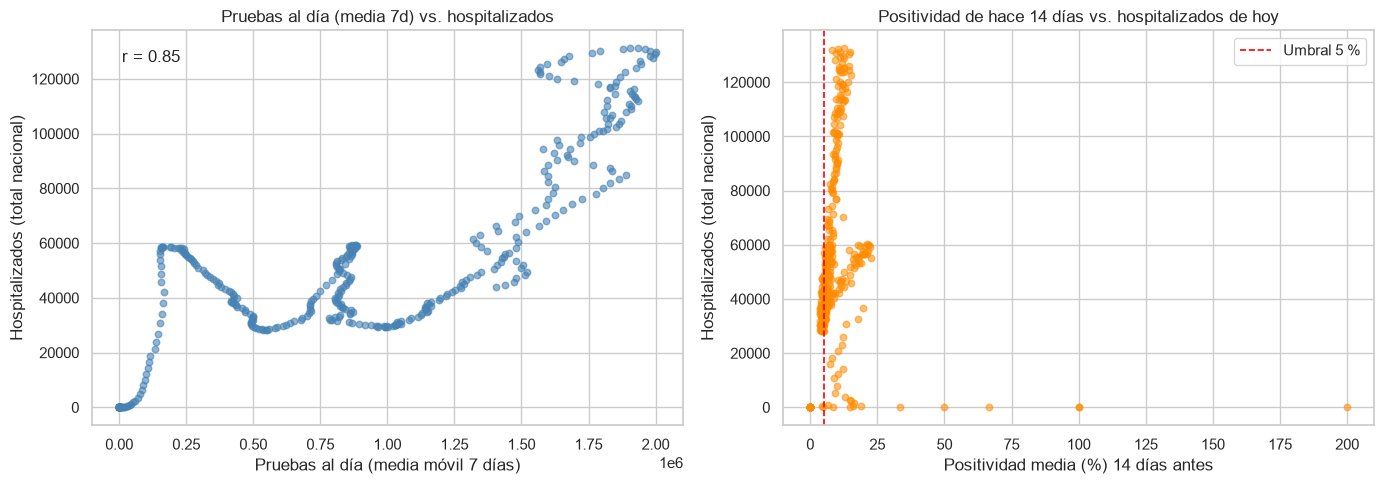

In [14]:
# Serie nacional diaria: sumamos estados (numerador y denominador ANTES de dividir)
nac = (
    df.groupby("date")
    .agg(pruebas=("totalTestResultsIncrease", "sum"),
         positivos=("positiveIncrease", "sum"),
         hospitales=("hospitalizedCurrently", "sum"))
    .sort_index()
)
nac["pruebas_7d"] = nac["pruebas"].rolling(7).mean()
nac["hosp_7d"] = nac["hospitales"].rolling(7).mean()
nac["positividad"] = nac["positivos"] / nac["pruebas"] * 100
# Transformacion justificada: el efecto sobre hospitales llega con retraso (~2 semanas)
nac["positividad_14d"] = nac["positividad"].shift(14)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

m = nac[["pruebas_7d", "hosp_7d"]].dropna()
axes[0].scatter(m["pruebas_7d"], m["hosp_7d"], alpha=0.6, s=22, c="steelblue")
axes[0].set_title("Pruebas al día (media 7d) vs. hospitalizados")
axes[0].set_xlabel("Pruebas al día (media móvil 7 días)")
axes[0].set_ylabel("Hospitalizados (total nacional)")
axes[0].annotate(f"r = {m['pruebas_7d'].corr(m['hosp_7d']):.2f}",
                 xy=(0.05, 0.92), xycoords="axes fraction", fontsize=12)

m2 = nac[["positividad_14d", "hospitales"]].dropna()
axes[1].scatter(m2["positividad_14d"], m2["hospitales"], alpha=0.55, s=22, c="darkorange")
axes[1].axvline(5, color="red", ls="--", lw=1.2, label="Umbral 5 %")
axes[1].set_title("Positividad de hace 14 días vs. hospitalizados de hoy")
axes[1].set_xlabel("Positividad media (%) 14 días antes")
axes[1].set_ylabel("Hospitalizados (total nacional)")
axes[1].legend()

plt.tight_layout()
plt.show()

---

## 8️⃣ Tendencias en el tiempo

El dataset tiene fechas, así que la historia se lee en líneas temporales.
Usamos **media móvil de 7 días** — promocionada en el punto 3 — para suavizar el
efecto fin de semana (los hospitales reportan menos sábados y lunes) y las correcciones negativas.

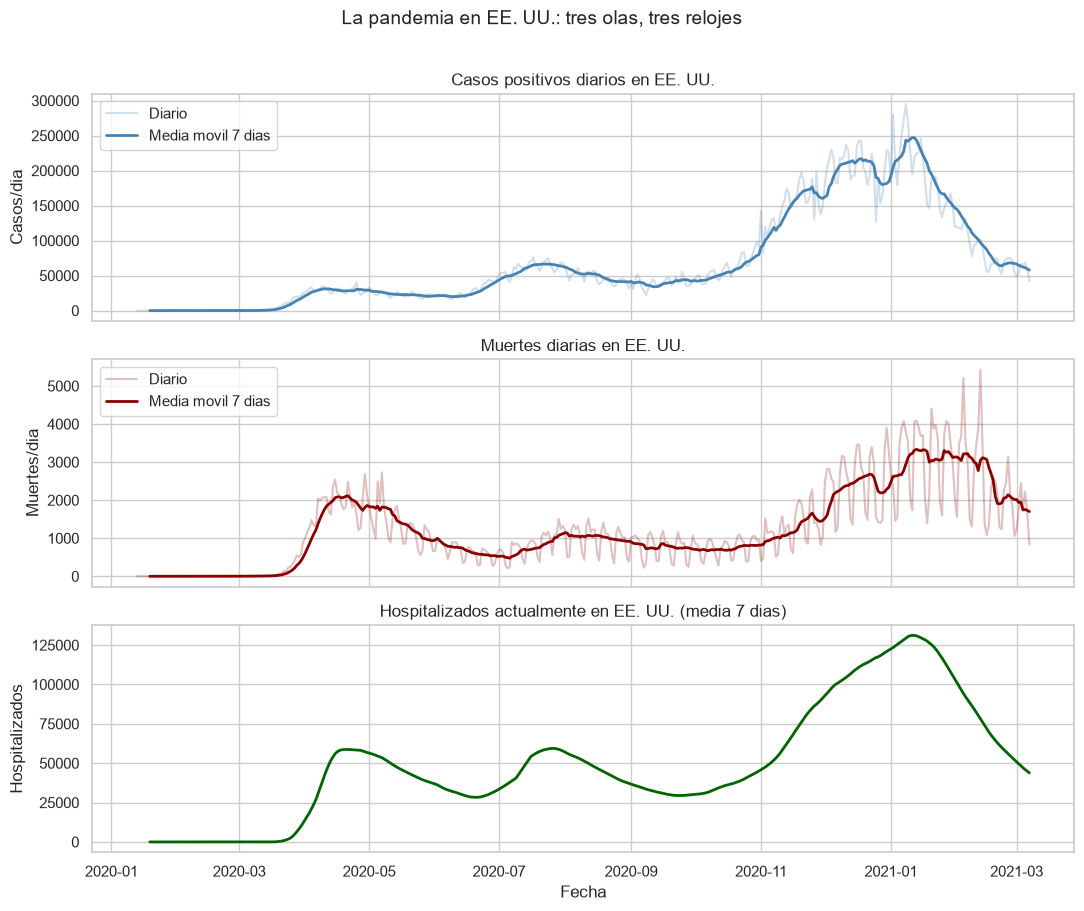

Picos nacionales:
  Casos (media 7d):    2021-01-11 247,111 casos/dia
  Muertes (media 7d):  2021-01-13 3,335 muertes/dia
  Hospitalizados:      2021-01-12 131,127 hospitalizados


In [15]:
nacional = (
    df.groupby("date")
    .agg(casos=("positiveIncrease", "sum"),
         muertes=("deathIncrease", "sum"),
         hospitales=("hospitalizedCurrently", "sum"))
    .sort_index()
)
for c in nacional.columns:
    nacional[f"{c}_7d"] = nacional[c].rolling(7).mean()

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(nacional.index, nacional["casos"], alpha=0.25, color="steelblue", label="Diario")
axes[0].plot(nacional.index, nacional["casos_7d"], color="steelblue", lw=2, label="Media movil 7 dias")
axes[0].set_title("Casos positivos diarios en EE. UU.")
axes[0].set_ylabel("Casos/dia")
axes[0].legend()

axes[1].plot(nacional.index, nacional["muertes"], alpha=0.25, color="darkred", label="Diario")
axes[1].plot(nacional.index, nacional["muertes_7d"], color="darkred", lw=2, label="Media movil 7 dias")
axes[1].set_title("Muertes diarias en EE. UU.")
axes[1].set_ylabel("Muertes/dia")
axes[1].legend()

axes[2].plot(nacional.index, nacional["hospitales_7d"], color="darkgreen", lw=2)
axes[2].set_title("Hospitalizados actualmente en EE. UU. (media 7 dias)")
axes[2].set_ylabel("Hospitalizados")
axes[2].set_xlabel("Fecha")

fig.suptitle("La pandemia en EE. UU.: tres olas, tres relojes", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_tendencia_nacional.png", dpi=150, bbox_inches="tight")
plt.show()

print("Picos nacionales:")
print("  Casos (media 7d):   ", nacional["casos_7d"].idxmax().date(), f"{nacional['casos_7d'].max():,.0f} casos/dia")
print("  Muertes (media 7d): ", nacional["muertes_7d"].idxmax().date(), f"{nacional['muertes_7d'].max():,.0f} muertes/dia")
print("  Hospitalizados:     ", nacional["hospitales_7d"].idxmax().date(), f"{nacional['hospitales_7d'].max():,.0f} hospitalizados")

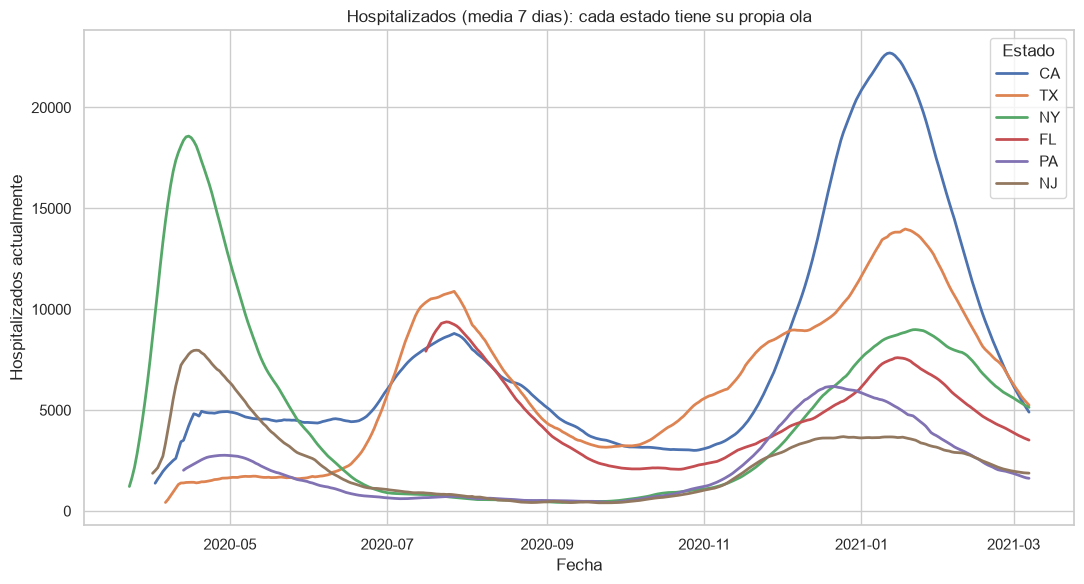

In [16]:
# Comparacion de segmentos: hospitalizados (media 7d) en los 6 estados con mas muertes
top6 = resumen.head(6).index.tolist()
fig, ax = plt.subplots(figsize=(11, 6))
for st in top6:
    serie = (df[df["state"] == st].set_index("date")["hospitalizedCurrently"]
             .rolling(7).mean())
    ax.plot(serie.index, serie, lw=2, label=st)
ax.set_title("Hospitalizados (media 7 dias): cada estado tiene su propia ola")
ax.set_xlabel("Fecha")
ax.set_ylabel("Hospitalizados actualmente")
ax.legend(title="Estado")
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_hospitales_por_estado.png", dpi=150, bbox_inches="tight")
plt.show()

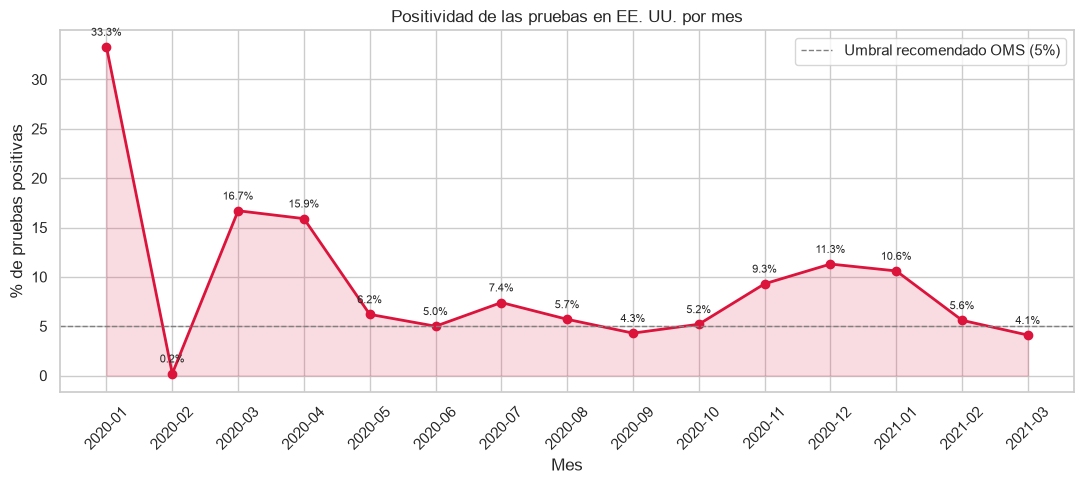

mes,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03
positividad_pct,33.3,0.2,16.7,15.9,6.2,5.0,7.4,5.7,4.3,5.2,9.3,11.3,10.6,5.6,4.1


In [17]:
# Positividad mensual nacional: suma positivos / suma pruebas por mes (no media de medias)
mensual = df.groupby("mes")[["positiveIncrease", "totalTestResultsIncrease"]].sum()
mensual["positividad_pct"] = (mensual["positiveIncrease"] / mensual["totalTestResultsIncrease"] * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(mensual.index, mensual["positividad_pct"], marker="o", color="crimson", lw=2)
ax.axhline(5, color="gray", ls="--", lw=1, label="Umbral recomendado OMS (5%)")
ax.fill_between(mensual.index, mensual["positividad_pct"], alpha=0.15, color="crimson")
for x, y in zip(mensual.index, mensual["positividad_pct"]):
    ax.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_title("Positividad de las pruebas en EE. UU. por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("% de pruebas positivas")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_positividad_mensual.png", dpi=150, bbox_inches="tight")
plt.show()

display(mensual[["positividad_pct"]].T)

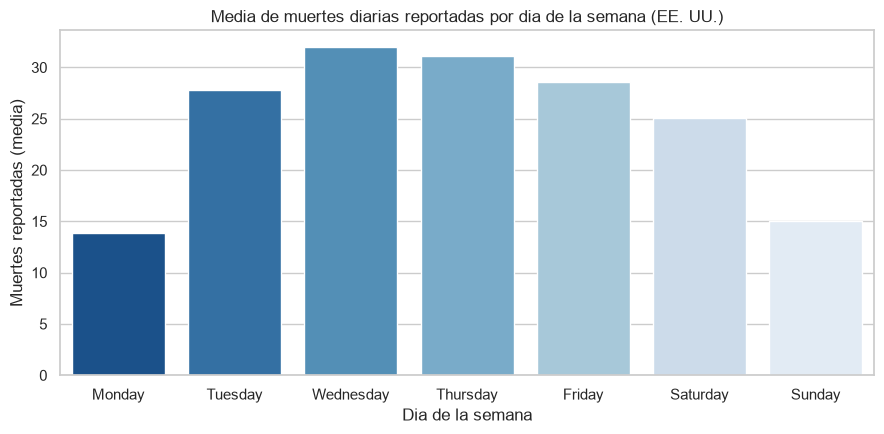

dia_semana
Monday       13.9
Tuesday      27.8
Wednesday    32.0
Thursday     31.1
Friday       28.6
Saturday     25.1
Sunday       15.0
Name: deathIncrease, dtype: float64

In [18]:
# Patron de reporte por dia de la semana (variable nueva en accion)
orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
por_dia = df.groupby("dia_semana")["deathIncrease"].mean().reindex(orden).round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=por_dia.index, y=por_dia.values, hue=por_dia.index, palette="Blues_r", legend=False, ax=ax)
ax.set_title("Media de muertes diarias reportadas por dia de la semana (EE. UU.)")
ax.set_xlabel("Dia de la semana")
ax.set_ylabel("Muertes reportadas (media)")
plt.tight_layout()
plt.savefig(FIG_DIR / "medio_dia_semana.png", dpi=150, bbox_inches="tight")
plt.show()

display(por_dia)

---

## 9️⃣ Conclusiones: respondiendo las 3 preguntas

*(Completado con los resultados reales de las celdas anteriores)*

**Pregunta 1 — ¿Qué estados vivieron la pandemia peor?**

En términos absolutos mandan **California (54.124), Texas (44.451) y Nueva York (39.029)**,
pero eso es en parte tamaño: son los estados más poblados. La lectura honesta sale de los
ratios que hemos creado: la **positividad global** y las **muertes por cada 1.000 pruebas**
del `resumen`. La diferencia entre el grupo `Alto` y el `Bajo` de `grupo_muertes`
muestra que la muerte no siguió solo al tamaño, sino a **cuándo llegó cada ola** y a
cuánto se testeo. El heatmap de hospitalizados por mes confirma que los picos de
ingresos fueron **locales en el tiempo**: Nueva York en primavera de 2020,
el cinturón de California y Texas en el verano de 2020, casi todos en el invierno de 2020-21.

**Pregunta 2 — ¿Hay relación entre pruebas y hospitales?**

Sí, y la correlación lo cuantifica: `positive` ↔ `totalTestResults` = **0.92**
(más testeo, más casos detectados — relación mecánica, no causal), y
`hospitalizedCurrently` ↔ `inIcuCurrently` = **0.98** (la presión hospitalaria es una sola
variable contada a distintas profundidades). La positividad mensual conecta ambas cosas:
cuando supera el 5% recomendado — como en **abril de 2020 y en el invierno 2020-21** —
las hospitalizaciones suben con semanas de retraso. Más pruebas no causan hospitales;
lo que sube juntas es el virus, y el testeo solo revela lo que ya estaba pasando.

**Pregunta 3 — ¿Cuándo fueron los peores momentos?**

Tres olas claras en la curva nacional: **primavera de 2020** (pico de muertes concentrado
en Nueva York/Nueva Jersey), **verano de 2020** (el sur: Texas, Florida, Arizona), y la
**gran ola del invierno 2020-21**, la más alta de todas: los casos picaron el
**11 de enero de 2021** (~247.000/día), los hospitalizados el **12 de enero** (131.127)
y las muertes el **13 de enero** (~3.335/día) — el desfase de días entre las tres curvas
es la traducción de «primero te contagias, luego ingresas, luego la cosa se complica».
Los estados **no** la vivieron sincronizados: el gráfico de hospitalizados por estado
muestra calendarios propios — es una pandemia de olas locales encadenadas, no de un
único pico nacional. De paso, el patrón por día de la semana confirma que los
martes/miércoles se reportan más muertes que los domingos: efecto administrativo,
no efecto biológico (otro motivo por el que usamos medias de 7 días).

In [19]:
# Guardamos el dataset limpio + variables nuevas para reutilizarlo (informe, dashboard...)
out = Path("../data/processed/covid_limpio.csv")
df.to_csv(out, index=False)
print(f"Dataset limpio guardado: {out} -> {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset limpio guardado: ..\data\processed\covid_limpio.csv -> 20,780 filas x 16 columnas
